# Proyecto 2 — Parte 3: Pronósticos BG/NBD vs. series de tiempo
**Business Intelligence · CDNOW · 1997–1998**

Notebook reproducible para los incisos **3.1, 3.2, 3.3 y 3.4**. Incluye carga y preparación de CDNOW, estimación BG/NBD por máxima verosimilitud (si no se proporcionan los parámetros de la Parte 2), gráficas, comparación de pronósticos y análisis por cliente.

**Importante:** los resultados no están precalculados: ejecuta las celdas con `CDNOW sample.txt`. No se usan datos inventados.

**Archivo de entrada:** `CDNOW_sample.zip` con `CDNOW_sample.txt` dentro, en la misma carpeta del notebook.

## 0. Preparación
Ejecuta este notebook **desde la carpeta `notebooks/`** del repositorio, en orden (Kernel → Restart & Run All). Los datos se leen de `../data/raw/CDNOW_sample.txt`, con cinco columnas sin encabezado: ID completo, ID de muestra, fecha AAAAMMDD, cantidad y monto. Las compras del mismo cliente en la misma fecha se consideran una transacción. Los CSV generados se guardan en `../data/processed/`.

In [1]:
# Si falta alguna dependencia, ejecuta esta línea una vez:
# %pip install numpy pandas scipy matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import hyp2f1, gammaln, betaln, logsumexp
from scipy.optimize import minimize
from pathlib import Path
import urllib.request

INICIO = pd.Timestamp('1997-01-01')
FIN_CAL = pd.Timestamp('1997-09-30')
INICIO_HOLD = pd.Timestamp('1997-10-01')
FIN_HOLD = pd.Timestamp('1998-06-30')

# Rutas de datos configuradas para el repositorio
from pathlib import Path
import urllib.request

URL_DATOS = (
    "https://raw.githubusercontent.com/"
    "xNoksS/bi-proyecto2-btyd/main/"
    "data/raw/CDNOW_sample.txt"
)

RUTA_DATOS = Path("/content/CDNOW_sample.txt")

urllib.request.urlretrieve(URL_DATOS, RUTA_DATOS)

print("✅ Base de datos descargada correctamente")
print("Ubicación:", RUTA_DATOS)

✅ Base de datos descargada correctamente
Ubicación: /content/CDNOW_sample.txt


In [2]:
import os
print(os.getcwd())
print(os.listdir())
print(os.path.exists("CDNOW_sample.txt"))

/content
['.config', 'CDNOW_sample.txt', 'resultados', 'sample_data']
True


### Preparación del calendario y de la historia individual
El período de evaluación son las **semanas 40–78**. Para graficar, usamos intervalos consecutivos de siete días a partir del 1 de enero de 1997; la semana 78 incluye hasta el 30 de junio de 1998 (el último intervalo puede quedar truncado). La partición de calibración/holdout usa las **fechas exactas del enunciado**. Esto implica que los intervalos semanales y la fecha de corte no coinciden perfectamente; se documenta esta convención para evitar mezclar información futura en el entrenamiento.

In [3]:
primera = compras.groupby('cliente')['fecha'].min().rename('primera')
compras = compras.join(primera, on='cliente')
compras['repetida'] = compras['fecha'] > compras['primera']
compras['semana'] = ((compras['fecha'] - INICIO).dt.days // 7 + 1).astype(int)

cal = compras[compras.fecha <= FIN_CAL].copy()
hold = compras[(compras.fecha >= INICIO_HOLD) & (compras.fecha <= FIN_HOLD)].copy()

def historial_cliente(g):
    fechas = g.fecha.sort_values()
    f0 = fechas.iloc[0]
    return pd.Series({
        'primera': f0,
        'x': len(fechas)-1,
        'tx': (fechas.iloc[-1]-f0).days/7 if len(fechas)>1 else 0.,
        'T': (FIN_CAL-f0).days/7
    })
clientes = cal.groupby('cliente').apply(historial_cliente, include_groups=False)
clientes['x_hold'] = hold.groupby('cliente').size().reindex(clientes.index, fill_value=0)
clientes['semana_inicio'] = ((clientes.primera-INICIO).dt.days//7 + 1).astype(int)
assert (clientes.T if False else clientes['T']).ge(clientes.tx).all()
assert (clientes['T'] >= 0).all()
display(clientes.head())
print('Clientes en calibración:',len(clientes))
print('Compras holdout:',clientes.x_hold.sum())

<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_7301/2203012497.py:5: SyntaxWarning: invalid escape sequence '\s'
  sep='\s+',


,primera,x,tx,T,x_hold,semana_inicio
cliente,,,,,,
4,1997-01-01,2,30.428571,38.857143,1,1
18,1997-01-04,0,0.000000,38.428571,0,1
21,1997-01-01,1,1.714286,38.857143,0,1
50,1997-01-01,0,0.000000,38.857143,0,1
60,1997-02-01,0,0.000000,34.428571,0,5


Clientes en calibración: 2357
Compras holdout: 1882


## Estimación de parámetros BG/NBD (apoyo de la Parte 2)
Si ya estimaste `r`, `alpha`, `a`, `b` en la Parte 2, puedes sustituirlos en la celda posterior. Si no, se estiman mediante máxima verosimilitud. La parametrización usa `Gamma(r, tasa=alpha)` y `Beta(a,b)`.

La log-verosimilitud implementa las dos posibilidades: cliente activo hasta el fin de observación o abandono después de la última recompra.

In [4]:
def loglik_bgnbd(theta_log, x, tx, T):
    r, alpha, a, b = np.exp(theta_log)
    A1 = gammaln(r+x)-gammaln(r)+r*np.log(alpha)
    A2 = gammaln(a+b)+gammaln(b+x)-gammaln(b)-gammaln(a+b+x)
    activo = -(r+x)*np.log(alpha+T)
    abandono = np.full_like(x, -np.inf, dtype=float)
    mask = x>0
    abandono[mask] = (np.log(a)-np.log(b+x[mask]-1)
                       -(r+x[mask])*np.log(alpha+tx[mask]))
    return A1 + A2 + np.logaddexp(activo, abandono)

x = clientes.x.to_numpy(dtype=float)
tx = clientes.tx.to_numpy(dtype=float)
T = clientes['T'].to_numpy(dtype=float)

def objetivo(theta):
    ll = loglik_bgnbd(theta,x,tx,T)
    return -np.sum(ll) if np.isfinite(ll).all() else 1e100

inicios = [[0.5, 5, 1.5, 3], [1, 10, 2, 5], [0.2, 2, 2, 4]]
ajustes = [minimize(objetivo, np.log(v), method='L-BFGS-B',
                    bounds=[(-12,12)]*4) for v in inicios]
mejor = min(ajustes,key=lambda q:q.fun)
if not mejor.success:
    print('Advertencia: revisar convergencia:', mejor.message)
r, alpha, a, b = np.exp(mejor.x)
print(dict(r=r, alpha=alpha, a=a, b=b))
print('Log-verosimilitud:',-mejor.fun)

# Para usar los parámetros estimados en tu Parte 2, descomenta y edita:
# r, alpha, a, b = 0.0, 0.0, 0.0, 0.0
assert min(r,alpha,a,b)>0
if a < 1:
    print('Nota: a < 1 es válido; no debe confundirse con a = 1.')

{'r': np.float64(0.24259433674582465), 'alpha': np.float64(4.4135959137069625), 'a': np.float64(0.7929228201454392), 'b': np.float64(2.42591013372967)}
Log-verosimilitud: -9582.429206674089
Nota: a < 1 es válido; no debe confundirse con a = 1.


## 3.1 Bottom-up: pronóstico por cohorte
La esperanza de compras repetidas de un cliente con antigüedad `t` desde su primera compra es:

\[
E[X(t)] = \frac{a+b-1}{a-1}\left[1-\left(\frac{\alpha}{\alpha+t}\right)^r {}_2F_1\left(r,b;a+b-1;\frac{t}{\alpha+t}\right)\right].
\]

Se suman las esperanzas para todos los clientes, desplazadas según su primera compra. La fórmula es válida para a < 1 (excepto el caso singular a = 1, que requiere un límite). El valor observado cuenta compras repetidas (no la primera compra).

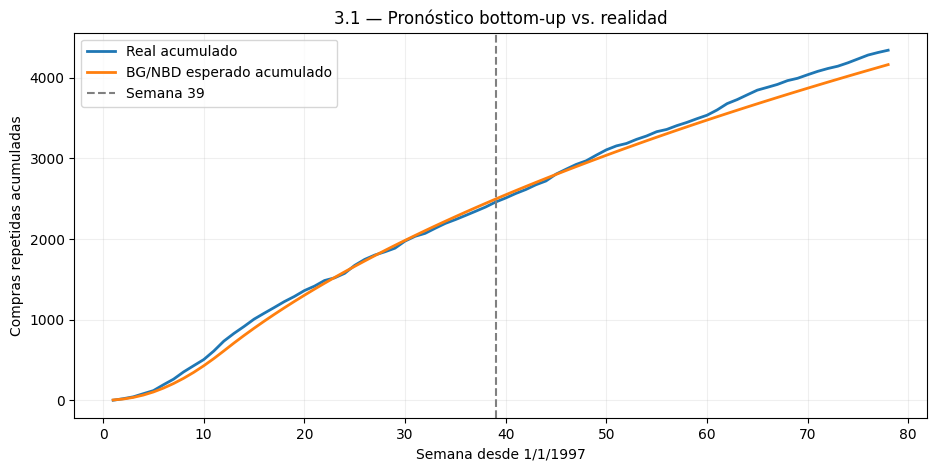

Pronóstico BG/NBD semanas 40–78: 1666.65
Real semanas 40–78: 1882


In [5]:
# 3.1: esperanza incondicional BG/NBD y curva acumulada
from scipy.special import hyp2f1

def ex_repetidas(t):
    t = np.maximum(np.asarray(t, dtype=float), 0)
    if np.isclose(a, 1.0, atol=1e-7):
        raise ValueError("a está demasiado cerca de 1; se requiere evaluación por límite.")
    z = t / (alpha + t)
    return ((a+b-1)/(a-1)) * (
        1 - (alpha/(alpha+t))**r *
        hyp2f1(r, b, a+b-1, z)
    )

semanas = np.arange(1, 79)
dias_corte = np.minimum(semanas*7-1, (FIN_HOLD-INICIO).days)
dias_primera = (clientes['primera']-INICIO).dt.days.to_numpy()
edad = np.maximum((dias_corte[:,None]-dias_primera[None,:])/7, 0)
pred_acum = np.sum(ex_repetidas(edad), axis=1)

real_semanal = (compras.loc[compras.repetida & compras.fecha.le(FIN_HOLD)]
                .groupby('semana').size().reindex(semanas, fill_value=0))
real_acum = real_semanal.cumsum().to_numpy()

plt.figure(figsize=(11,5))
plt.plot(semanas, real_acum, label='Real acumulado', lw=2)
plt.plot(semanas, pred_acum, label='BG/NBD esperado acumulado', lw=2)
plt.axvline(39, ls='--', color='gray', label='Semana 39')
plt.xlabel('Semana desde 1/1/1997')
plt.ylabel('Compras repetidas acumuladas')
plt.title('3.1 — Pronóstico bottom-up vs. realidad')
plt.legend(); plt.grid(alpha=.2); plt.show()
print('Pronóstico BG/NBD semanas 40–78:', round(pred_acum[-1]-pred_acum[38], 2))
print('Real semanas 40–78:', int(real_semanal.loc[40:78].sum()))


## 3.2 Top-down: pronóstico agregado
Se usan únicamente las primeras 39 observaciones semanales. Se comparan cuatro familias: media histórica, naïve, media móvil de 4 y 8 semanas, y tendencia lineal con ventanas de 13 y 26 semanas. Los pronósticos negativos se truncan a cero.

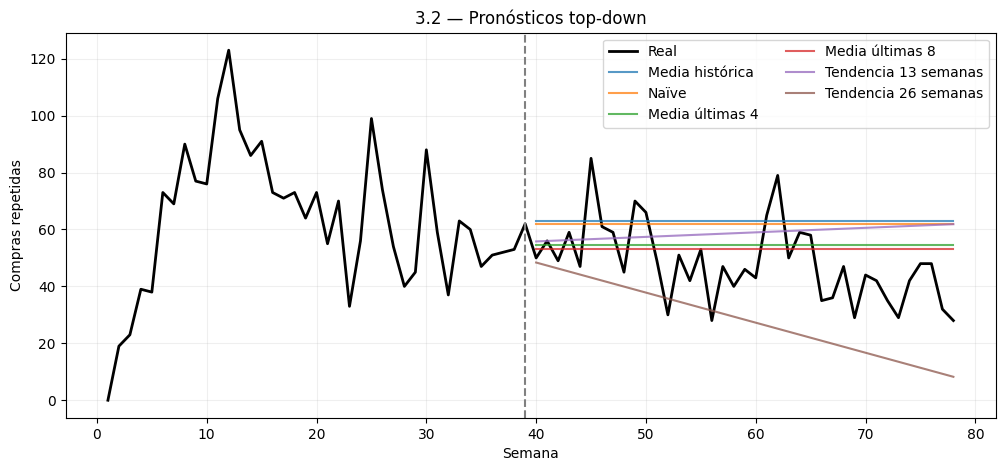

In [6]:
train = real_semanal.loc[1:39].astype(float)
test = real_semanal.loc[40:78].astype(float)
h = np.arange(1,40)
pronosticos = {}
pronosticos['Media histórica'] = np.repeat(train.mean(),39)
pronosticos['Naïve'] = np.repeat(train.iloc[-1],39)
for v in [4,8]:
    pronosticos[f'Media últimas {v}'] = np.repeat(train.iloc[-v:].mean(),39)
for v in [13,26]:
    ys = train.iloc[-v:].to_numpy()
    xs = np.arange(39-v+1,40)
    m,c = np.polyfit(xs,ys,1)
    pronosticos[f'Tendencia {v} semanas'] = np.maximum(m*np.arange(40,79)+c,0)

plt.figure(figsize=(12,5))
plt.plot(np.arange(1,79),real_semanal.values,label='Real',color='black',lw=2)
for nombre,yhat in pronosticos.items():
    plt.plot(np.arange(40,79),yhat,label=nombre,alpha=.75)
plt.axvline(39,color='gray',ls='--')
plt.title('3.2 — Pronósticos top-down');plt.xlabel('Semana')
plt.ylabel('Compras repetidas');plt.legend(ncol=2);plt.grid(alpha=.2);plt.show()

## 3.3 Comparación de modelos
El error porcentual firmado se calcula como `(pronóstico − real)/real × 100`. El **MAE semanal** es la media de los errores absolutos semanales. Para la comparación se deriva el pronóstico semanal BG/NBD restando acumulados sucesivos.

**Precaución metodológica:** el BG/NBD incondicional de 3.1 se ajustó con calibración y pronostica desde el inicio de cada cliente; para una comparación estrictamente fuera de muestra, los métodos deben evaluarse sobre los mismos cortes temporales. La convención semanal puede diferir en hasta unos días del corte calendario exacto.

In [7]:
# BG/NBD semanal: incrementos del acumulado
pred_sem_bgnbd = np.diff(np.r_[0,pred_acum])[39:78]
pronosticos['BG/NBD bottom-up'] = pred_sem_bgnbd
real_h = test.to_numpy()
total_real = real_h.sum()
filas = []
for nombre,p in pronosticos.items():
    p = np.asarray(p,float)
    filas.append({
        'Método':nombre,
        'Total pronosticado':round(p.sum(),2),
        'Total real':int(total_real),
        'Error porcentual (%)':round(100*(p.sum()-total_real)/total_real,2),
        'MAE semanal':round(np.mean(np.abs(p-real_h)),2)
    })
tabla = pd.DataFrame(filas).sort_values('MAE semanal')
display(tabla)
print('Mejor MAE:',tabla.iloc[0]['Método'])
print('Compras repetidas semanas 1–12:',int(real_semanal.loc[1:12].sum()))
from pathlib import Path

RUTA_SALIDAS = Path("/content/resultados")
RUTA_SALIDAS.mkdir(parents=True, exist_ok=True)
tabla.to_csv(RUTA_SALIDAS / 'parte3_comparacion_modelos.csv', index=False)

,Método,Total pronosticado,Total real,Error porcentual (%),MAE semanal
6,BG/NBD bottom-up,1666.65,1882,-11.44,9.82
3,Media últimas 8,2071.88,1882,10.09,11.67
2,Media últimas 4,2125.50,1882,12.94,12.27
4,Tendencia 13 semanas,2294.57,1882,21.92,14.90
1,Naïve,2418.00,1882,28.48,16.56
0,Media histórica,2457.00,1882,30.55,17.31
5,Tendencia 26 semanas,1104.07,1882,-41.34,20.42


Mejor MAE: BG/NBD bottom-up
Compras repetidas semanas 1–12: 733


In [8]:

print("r =", r)
print("alpha =", alpha)
print("a =", a)
print("b =", b)


r = 0.24259433674582465
alpha = 4.4135959137069625
a = 0.7929228201454392
b = 2.42591013372967


## 3.4 Pronóstico por cliente condicionado a su historia
Para cada cliente se calcula `E[Y(39) | x, tx, T]` con la fórmula condicional del enunciado. Se agrupan por `x` de calibración: 0,1,...,6 y 7+. Se compara la media pronosticada y observada `x*`.

\[
A=\frac{\alpha+T}{\alpha+T+\tau},\quad
D=1+\mathbf{1}_{x>0}\frac{a}{b+x-1}
\left(\frac{\alpha+T}{\alpha+t_x}\right)^{r+x}.
\]

,clientes,promedio_predicho,promedio_real,error
grupo,,,,
0,1411,0.225087,0.236712,-0.011624
1,439,0.523131,0.697039,-0.173908
2,214,1.044134,1.392523,-0.348389
3,100,1.520279,1.560000,-0.039721
4,62,2.163865,2.532258,-0.368393
5,38,2.653845,2.947368,-0.293523
6,29,3.504041,3.862069,-0.358028
7+,64,6.157189,6.359375,-0.202186


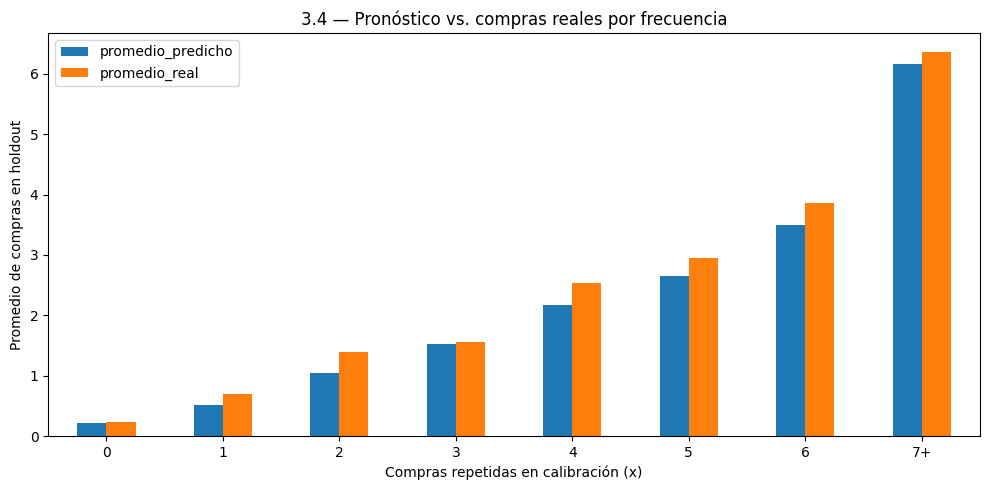

In [9]:
def pronostico_condicional(x,tx,T,tau=39):
    x=np.asarray(x,float); tx=np.asarray(tx,float); T=np.asarray(T,float)
    A=(alpha+T)/(alpha+T+tau)
    D=np.ones_like(x)
    mask=x>0
    D[mask] += (a/(b+x[mask]-1))*(
        (alpha+T[mask])/(alpha+tx[mask]))**(r+x[mask])
    if np.isclose(a, 1.0, atol=1e-7):
        raise ValueError('a está demasiado cerca de 1; requiere evaluación por límite.')
    num = 1-A**(r+x)*hyp2f1(r+x,b+x,a+b+x-1,1-A)
    return ((a+b+x-1)/(a-1))*num/D

clientes['pred_hold'] = pronostico_condicional(x,tx,T,39)
clientes['grupo'] = clientes.x.apply(lambda n:str(int(n)) if n<7 else '7+')
grupos = (clientes.groupby('grupo')
          .agg(clientes=('x','size'),
               promedio_predicho=('pred_hold','mean'),
               promedio_real=('x_hold','mean'))
          .reindex([str(i) for i in range(7)]+['7+']))
grupos['error'] = grupos.promedio_predicho-grupos.promedio_real
display(grupos)
ax=grupos[['promedio_predicho','promedio_real']].plot.bar(figsize=(10,5))
ax.set_title('3.4 — Pronóstico vs. compras reales por frecuencia')
ax.set_xlabel('Compras repetidas en calibración (x)')
ax.set_ylabel('Promedio de compras en holdout')
plt.xticks(rotation=0);plt.tight_layout();plt.show()
grupos.to_csv(RUTA_SALIDAS / 'parte3_por_cliente.csv')

## Conclusiones de la Parte 3

**3.1. Pronóstico bottom-up con BG/NBD.** El modelo BG/NBD estimó **1,666.65 compras repetidas** para las semanas 40 a 78, frente a **1,882 compras observadas**. La diferencia representa una **subestimación del 11.4 %**. Aunque el pronóstico no reproduce exactamente el volumen real, permite estimar la demanda futura a partir del historial de compras de cada cliente y agregar esas estimaciones para obtener el total.

**3.2. Pronósticos top-down.** Se construyeron alternativas agregadas utilizando únicamente las semanas 1 a 39: media histórica, método naïve, medias móviles de 4 y 8 semanas y tendencias de 13 y 26 semanas. Estos métodos proporcionan puntos de comparación que no requieren modelar individualmente la frecuencia de compra y la deserción de los clientes.

**3.3. Comparación de métodos.** El **BG/NBD bottom-up obtuvo el menor error absoluto medio semanal (MAE = 9.82)** entre los métodos evaluados. Por tanto, fue el más preciso para estimar el número de compras semana a semana, aunque su pronóstico acumulado quedó por debajo del total observado. Conviene distinguir entre el MAE semanal y el error porcentual del total: una mejor precisión semanal no garantiza que el error acumulado sea el menor.

**3.4. Pronóstico condicionado a la historia del cliente.** El enfoque BG/NBD permite estimar compras futuras en función de la frecuencia de compras repetidas (`x`), la recencia (`tx`) y el tiempo de observación (`T`). La comparación por grupos de frecuencia (de 0 a 6 y 7 o más compras) permite examinar dónde las predicciones se acercan o se alejan del comportamiento real. Esta desagregación aporta información que los métodos top-down, al trabajar con totales semanales, no ofrecen directamente.

**Conclusión general.** En este ejercicio, BG/NBD ofreció el mejor desempeño en términos de MAE semanal, pero subestimó el total de compras del período de validación. Por ello, resulta útil para proyectar la actividad de compra y analizar diferencias entre clientes, siempre que sus resultados se contrasten con datos observados y se vigile la posible subestimación agregada.

> **Nota de interpretación:** las compras repetidas no equivalen a clientes nuevos. Para medir adquisición deben identificarse las primeras compras de cada cliente.

Las cifras anteriores corresponden a los resultados de referencia de la revisión del proyecto. La siguiente celda conserva las conclusiones calculadas automáticamente para contrastarlas con los valores obtenidos al ejecutar el notebook.

In [10]:
# Conclusiones reproducibles basadas en los resultados de esta ejecución
fila_bg = tabla.loc[tabla['Método'].eq('BG/NBD bottom-up')].iloc[0]
mejor_mae = tabla.sort_values('MAE semanal').iloc[0]
mejor_total = tabla.loc[tabla['Error porcentual (%)'].abs().idxmin()]
err_bg = float(fila_bg['Error porcentual (%)'])
print('CONCLUSIONES DE LA PARTE 3\n')
print(f"3.1 Bottom-up: durante las semanas 40–78 se registraron {int(total_real):,} compras repetidas y BG/NBD pronosticó {float(fila_bg['Total pronosticado']):,.2f}. Su error porcentual firmado fue {err_bg:.2f}%; " + ('sobreestimó' if err_bg>0 else 'subestimó' if err_bg<0 else 'igualó') + ' el total observado.')
print(f"3.2 Top-down: se evaluaron la media histórica, el método naïve, medias móviles de 4 y 8 semanas y tendencias de 13 y 26 semanas, usando exclusivamente las semanas 1–39 para construir sus pronósticos.")
print(f"3.3 Comparación: el menor MAE semanal correspondió a {mejor_mae['Método']} ({float(mejor_mae['MAE semanal']):.2f}); el menor error porcentual absoluto del total correspondió a {mejor_total['Método']} ({abs(float(mejor_total['Error porcentual (%)'])):.2f}%). Estas métricas evalúan aspectos distintos del pronóstico.")
gval = grupos.dropna(subset=['error']).copy()
if not gval.empty:
    grupo_max = gval['error'].abs().idxmax()
    print(f"3.4 Clientes: el grupo con mayor diferencia absoluta entre promedio predicho y observado fue x={grupo_max}, con diferencia firmada de {float(gval.loc[grupo_max,'error']):.3f} compras por cliente. BG/NBD permite pronosticar por historial individual, a diferencia de los métodos agregados top-down.")
print(f"Primeras 12 semanas: se observaron {int(real_semanal.loc[1:12].sum()):,} compras repetidas. Esta cifra no equivale al número de clientes nuevos; para analizar entradas se deben contar las primeras compras por semana.")


CONCLUSIONES DE LA PARTE 3

3.1 Bottom-up: durante las semanas 40–78 se registraron 1,882 compras repetidas y BG/NBD pronosticó 1,666.65. Su error porcentual firmado fue -11.44%; subestimó el total observado.
3.2 Top-down: se evaluaron la media histórica, el método naïve, medias móviles de 4 y 8 semanas y tendencias de 13 y 26 semanas, usando exclusivamente las semanas 1–39 para construir sus pronósticos.
3.3 Comparación: el menor MAE semanal correspondió a BG/NBD bottom-up (9.82); el menor error porcentual absoluto del total correspondió a Media últimas 8 (10.09%). Estas métricas evalúan aspectos distintos del pronóstico.
3.4 Clientes: el grupo con mayor diferencia absoluta entre promedio predicho y observado fue x=4, con diferencia firmada de -0.368 compras por cliente. BG/NBD permite pronosticar por historial individual, a diferencia de los métodos agregados top-down.
Primeras 12 semanas: se observaron 733 compras repetidas. Esta cifra no equivale al número de clientes nuevos; para 